# DataVerso 002 · Brazilian first names in Censo 2022

IBGE's *Nomes no Brasil* counts the first names of the people living in Brazil on 1 August 2022, the reference date of Censo Demográfico 2022, for the whole country, by sex and by birth decade. The [project notes](README.md) describe the data, their provenance and IBGE's counting rules; `build.py` turns IBGE's API responses into the tables read here.

The notebook first audits what the tables cover, then asks four questions:

1. How concentrated were first names in each birth decade?
2. Which names mark a generation?
3. How did Maria, Ana, João and José move across the decades?
4. How often do a few spelling patterns appear, and in which decades?

Every share uses the people listed in the relevant table as its denominator, for the reasons given in section 3.2.

## 1. Setup

Install this project environment with `uv sync --project projects/002-nomes-brasil` from the repository root, and select its `.venv/bin/python` as the notebook kernel. The notebook reads `data/processed/` and writes its results tables to `results/`, both beside it. The plots are drafts for reading the shapes; the published figures are drawn separately.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

In [2]:
PROCESSED_DIR = Path("data/processed")
RESULTS_DIR = Path("results")

# Census reference date: 1 August 2022
REFERENCE_YEAR = 2022
FIRST_DECADE, LAST_DECADE = 1930, 2020  # IBGE's oldest and youngest birth-decade labels

# Sections 4 and 6: the four most common first names in the national table
HEADS = ["maria", "ana", "joao", "jose"]

# Section 4.1: IBGE lists a name in a decade only when at least this many people bear it
DISCLOSURE_THRESHOLD = 20

# Sections 3.3 and 7: a name belongs to a sex class when at least this share of its bearers
# is of that sex
SEX_CLASS_THRESHOLD = 0.95

# Section 5: distinctive names
DISTINCTIVE_MIN_SHARE = 0.0005  # 1 in 2,000 listed people of the decade
DISTINCTIVE_TOP = 20  # names kept per decade
SMOOTHING = 0.5  # added to the pooled count and to the pooled total of the other decades

# Section 7: spelling patterns, matched with re.search on IBGE's lower-case form
SPELLING_PATTERNS = {
    "kwy": r"[kwy]",
    "th": r"th",
    "double_consonant": r"(bb|dd|ff|gg|ll|mm|nn|pp|tt|zz)",
    "son_ending": r"son$",
    "ton_ending": r"ton$",
}

## 2. Data

`build.py` wrote four tables from IBGE's responses and checked them; `manifest.json` records when the responses were retrieved, the size of each ranking query and the result of each check.

- `names_total`: one row per name, for the whole country.
- `names_decade`: one row per birth-decade label and name.
- `names_sex`: one row per sex and name.
- `census_age_sex`: the resident population by single year of age (100 standing for 100 or more) and sex, from SIDRA table 9514.

The name tables are sorted as every measure below reads them: by count, largest first, then by name.

In [3]:
names_total = pd.read_parquet(PROCESSED_DIR / "names_total.parquet")
names_decade = pd.read_parquet(PROCESSED_DIR / "names_decade.parquet")
names_sex = pd.read_parquet(PROCESSED_DIR / "names_sex.parquet")
census = pd.read_parquet(PROCESSED_DIR / "census_age_sex.parquet")
manifest = json.loads((PROCESSED_DIR / "manifest.json").read_text(encoding="utf-8"))

# The ordering used throughout: count descending, then name ascending, within each decade
names_total = names_total.sort_values(["count", "name"], ascending=[False, True], ignore_index=True)
names_decade = names_decade.sort_values(
    ["decade", "count", "name"], ascending=[True, False, True], ignore_index=True
)

retrieved = manifest["retrieved"]
passed = sum(check["result"] == "pass" for check in manifest["checks"])
print(f"Retrieved from {retrieved['start']} to {retrieved['end']}")
print(f"{passed} of {len(manifest['checks'])} data checks passed")
for table_name, table in {
    "names_total": names_total,
    "names_decade": names_decade,
    "names_sex": names_sex,
    "census_age_sex": census,
}.items():
    print(f"{table_name}: {len(table):,} rows")
display(pd.DataFrame(manifest["queries"]).T[["count", "totalPages"]])

Retrieved from 2026-11-26T13:37:43+00:00 to 2026-11-26T13:49:11+00:00
34 of 34 data checks passed
names_total: 128,458 rows
names_decade: 221,524 rows
names_sex: 134,315 rows
census_age_sex: 303 rows


,count,totalPages
decade_1930,5965,199
decade_1940,11959,399
decade_1950,18557,619
decade_1960,25887,863
decade_1970,32071,1070
decade_1980,37381,1247
decade_1990,34571,1153
decade_2000,27374,913
decade_2010,18774,626
decade_2020,8985,300


## 3. Audit

### 3.1 How much of the population the tables cover

The national table lists only names given to at least 20 people, and the decade table applies the same threshold within each decade. Summing their counts gives the residents each one accounts for, which the census population puts in proportion.

In [4]:
population = census.loc[census["sex"] == "total", "population"].sum()
national_people = names_total["count"].sum()
decade_people = names_decade["count"].sum()

print(f"Resident population: {population:>12,}")
print(f"National table:      {national_people:>12,} ({national_people / population:.1%})")
print(f"Decade table:        {decade_people:>12,} ({decade_people / population:.1%})")

Resident population:  203,080,756
National table:       190,383,184 (93.7%)
Decade table:         186,340,745 (91.8%)


### 3.2 Birth-decade labels against census ages

IBGE does not define the boundaries of its birth-decade labels. Under the *plain reading*, a resident aged $a$ on the reference date was born in $2022 - a$ and belongs to the decade

$$d(a) = \min\left(2020,\ \max\left(1930,\ \left\lfloor \frac{2022 - a}{10} \right\rfloor \times 10\right)\right),$$

so the oldest label takes everyone born before 1940 and the youngest everyone born from 2020. The coverage of a label is the number of people it lists, $L_d$, over the census population of its ages under that reading.

In [5]:
census_total = census[census["sex"] == "total"].copy()
census_total["decade"] = ((REFERENCE_YEAR - census_total["age"]) // 10 * 10).clip(
    FIRST_DECADE, LAST_DECADE
)

coverage = pd.DataFrame(
    {
        "listed_people": names_decade.groupby("decade")["count"].sum(),
        "census_people_plain": census_total.groupby("decade")["population"].sum(),
    }
).reset_index()
coverage["coverage_plain"] = coverage["listed_people"] / coverage["census_people_plain"]
display(coverage)

,decade,listed_people,census_people_plain,coverage_plain
0,1930,2539832,2943839,0.862762
1,1940,6840789,7542995,0.906906
2,1950,14145527,15374806,0.920046
3,1960,20796151,22627635,0.919060
4,1970,24951988,27349282,0.912345
5,1980,29633691,32573218,0.909756
6,1990,28181790,30900953,0.912004
7,2000,26966075,29120603,0.926014
8,2010,23011680,27371796,0.840708
9,2020,9273222,7275629,1.274559


The bearers of the most common names can be followed from the national table into the decade table. People aged 93 or more on the reference date were all born before 1930.

In [6]:
in_decades = names_decade.groupby("name")["count"].sum()
most_common = names_total.head(20).set_index("name")["count"]
decade_gaps = pd.DataFrame(
    {
        "national": most_common,
        "in_decades": in_decades.reindex(most_common.index),
    }
)
decade_gaps["not_in_any_decade"] = decade_gaps["national"] - decade_gaps["in_decades"]

born_before_1930 = census_total.loc[census_total["age"] >= 93, "population"].sum()
print(f"Residents aged 93 or more: {born_before_1930:,}")
display(decade_gaps)

Residents aged 93 or more: 359,952


,national,in_decades,not_in_any_decade
name,,,
maria,12284478,12284474,4
jose,5164752,5164750,2
ana,3948650,3948644,6
joao,3430608,3430596,12
antonio,2241094,2241082,12
francisco,1665494,1665492,2
pedro,1624478,1624473,5
carlos,1474492,1474484,8
lucas,1341525,1341522,3


Under the plain reading, the labels from 1940 to 2000 list between 91% and 93% of the census population of their ages (90.7% to 92.6%), close to the 91.8% that the decade table covers overall. The 2010 and 2020 labels do not fit it. The 2010 label lists 84% of the residents aged 3 to 12, and the 2020 label lists more people (9,273,222) than the census counts at ages 0 to 2 (7,275,629), which a threshold that only removes people cannot produce. The 1930 label evidently includes earlier births: each of the twenty most common names keeps all but at most 20 of its bearers across the ten labels, although 359,952 residents were aged 93 or more on the reference date and so born before 1930.

The labels are therefore treated as categories, and every share in this notebook uses the people listed under a label, $L_d$, as its denominator, never a census population.

### 3.3 Sex classes

A name's sex class comes from its female and male counts, $f$ and $m$, in `names_sex` and its total $t$ in `names_total`. A name missing from one sex table has fewer than 20 bearers of that sex, and that count is taken as 0. The class is

$$\text{class} = \begin{cases} f & \text{if } f / t \ge 0.95 \\ m & \text{if } m / t \ge 0.95 \\ \text{other} & \text{otherwise.} \end{cases}$$

The coverage table gives, for each decade, the listed people in each class as a share of all listed people of that decade.

In [7]:
# Female and male counts per name, 0 where the name is missing from that sex's table
by_sex = names_sex.pivot(index="name", columns="sex", values="count")
name_classes = names_total.set_index("name")[["count"]].join(by_sex).fillna(0).astype("int64")
name_classes["sex_class"] = np.select(
    [
        name_classes["f"] / name_classes["count"] >= SEX_CLASS_THRESHOLD,
        name_classes["m"] / name_classes["count"] >= SEX_CLASS_THRESHOLD,
    ],
    ["f", "m"],
    default="other",
)

decade_rows = names_decade.join(name_classes["sex_class"], on="name")
sex_class_coverage = (
    decade_rows.groupby(["decade", "sex_class"])["count"].sum().rename("people").reset_index()
)
sex_class_coverage["share"] = sex_class_coverage["people"] / sex_class_coverage.groupby("decade")[
    "people"
].transform("sum")

in_neither = (name_classes["f"] == 0) & (name_classes["m"] == 0)
print(name_classes["sex_class"].value_counts().to_string())
print(f"Names in neither sex table (class other by construction): {in_neither.sum():,}")
display(sex_class_coverage.pivot(index="decade", columns="sex_class", values="share"))

sex_class
f        57508
m        45286
other    25664
Names in neither sex table (class other by construction): 4,725


sex_class,f,m,other
decade,,,
1930,0.615821,0.354205,0.029974
1940,0.546775,0.414951,0.038273
1950,0.522942,0.437945,0.039112
1960,0.508788,0.448353,0.042859
1970,0.501250,0.459962,0.038787
1980,0.503183,0.470766,0.026051
1990,0.497741,0.484968,0.017291
2000,0.483970,0.504326,0.011703
2010,0.482796,0.509177,0.008027


Of the 128,458 names in the national table, 57,508 are in class `f`, 45,286 in `m` and 25,664 in `other`. Of the `other` names, 4,725 appear in neither sex table, because each sex has fewer than 20 bearers of them, and fall in `other` by construction; they are rarely listed in a decade. Weighted by people, `other` is small: between 0.8% (2010) and 4.3% (1960) of the listed people of a decade. The class of a name is national, so a name keeps one class in every decade. The `f` class holds 62% of the listed people of 1930 and about 48% from 2000 on.

## 4. How concentrated were first names in each birth decade?

For decade $d$, the listed people are $L_d = \sum_i c_{d,i}$ and the share of name $i$ is $p_{d,i} = c_{d,i} / L_d$. With the names in the ordering, $p_{(1)} \ge p_{(2)} \ge \dots$:

- the top-$k$ share is $\sum_{r=1}^{k} p_{(r)}$, for $k$ = 1, 10 and 100;
- $n_{50} = \min\left\{k : \sum_{r=1}^{k} p_{(r)} \ge 0.5\right\}$ is the number of names that together account for half of the listed people;
- the Hill numbers ${}^{1}D = \exp\left(-\sum_i p_i \ln p_i\right)$ and ${}^{2}D = 1 / \sum_i p_i^2$ are effective numbers of names: a decade in which $n$ names were equally common has ${}^{1}D = {}^{2}D = n$. ${}^{2}D$ is driven by the commonest names, ${}^{1}D$ weighs every name by its share.

The table leaves out names given to fewer than 20 people in a decade. They would add small shares, which ${}^{1}D$ counts more heavily than ${}^{2}D$, so ${}^{1}D$ is the more sensitive of the two to that threshold.

The set `without_heads` removes `maria`, `ana`, `joao` and `jose` and recomputes $L_d$ and every share without them.

In [8]:
keys = ["decade", "set"]
ranked = pd.concat(
    [
        names_decade.assign(set="all"),
        names_decade[~names_decade["name"].isin(HEADS)].assign(set="without_heads"),
    ],
    ignore_index=True,
).sort_values(["decade", "set", "count", "name"], ascending=[True, True, False, True])

ranked["listed_people"] = ranked.groupby(keys)["count"].transform("sum")
ranked["share"] = ranked["count"] / ranked["listed_people"]
ranked["position"] = ranked.groupby(keys).cumcount() + 1
ranked["cumulative"] = ranked.groupby(keys)["count"].cumsum()
ranked["entropy_term"] = -ranked["share"] * np.log(ranked["share"])
ranked["simpson_term"] = ranked["share"] ** 2

grouped = ranked.groupby(keys)
first = ranked[ranked["position"] == 1].set_index(keys)
diversity = pd.DataFrame(
    {
        "listed_people": grouped["count"].sum(),
        "listed_names": grouped.size(),
        "top1_name": first["name"],
        "top1_share": first["share"],
        # Summed counts over L_d equal the summed shares, with a single rounding
        "top10_share": ranked[ranked["position"] <= 10].groupby(keys)["count"].sum()
        / grouped["count"].sum(),
        "top100_share": ranked[ranked["position"] <= 100].groupby(keys)["count"].sum()
        / grouped["count"].sum(),
        # The first position at which the running count reaches half of L_d; doubling the
        # integer counts keeps the comparison with one half exact
        "n50": ranked[2 * ranked["cumulative"] >= ranked["listed_people"]]
        .groupby(keys)["position"]
        .min(),
        "hill_q1": np.exp(grouped["entropy_term"].sum()),
        "hill_q2": 1 / grouped["simpson_term"].sum(),
    }
).reset_index()
display(diversity)

,decade,set,listed_people,listed_names,top1_name,top1_share,top10_share,top100_share,n50,hill_q1,hill_q2
0,1930,all,2539832,5965,maria,0.167515,0.334267,0.582318,52,378.654919,29.580753
1,1930,without_heads,1892314,5961,antonio,0.034606,0.147242,0.446052,139,969.732994,239.173302
2,1940,all,6840789,11959,maria,0.163888,0.342232,0.579125,52,426.345598,29.543975
3,1940,without_heads,5056678,11955,antonio,0.040744,0.150841,0.437130,149,1173.224361,223.501238
4,1950,all,14145527,18557,maria,0.159869,0.339661,0.580336,52,442.453753,30.561053
5,1950,without_heads,10491103,18553,antonio,0.038816,0.147645,0.440920,143,1208.206587,227.602202
6,1960,all,20796151,25887,maria,0.118272,0.280378,0.526924,83,668.997562,51.027135
7,1960,without_heads,16548108,25883,antonio,0.028871,0.125086,0.412505,163,1431.849775,295.475017
8,1970,all,24951988,32071,maria,0.064624,0.191123,0.472421,118,1054.346115,127.799354
9,1970,without_heads,21797546,32067,antonio,0.017951,0.107143,0.403806,169,1579.615193,376.946120


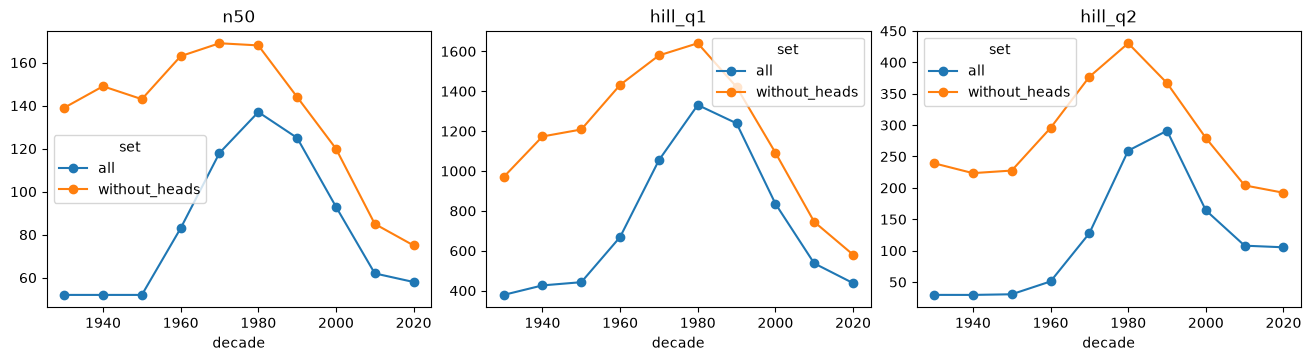

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
for ax, measure in zip(axes, ["n50", "hill_q1", "hill_q2"], strict=True):
    diversity.pivot(index="decade", columns="set", values=measure).plot(
        ax=ax, marker="o", title=measure
    )
plt.show()

With every name counted, half of the listed people of 1930, 1940 and 1950 bear one of 52 names, and `maria` alone accounts for 16% to 17% of them. Concentration then falls: $n_{50}$ reaches 137 in 1980 and ${}^{2}D$ reaches 291 in 1990. It rises again from 2000, to $n_{50} = 58$ and ${}^{2}D = 105$ in 2020.

Without the four heads, the oldest decades are far less concentrated (${}^{2}D$ is 239 in 1930, against 30 with them), and $n_{50}$ stays between 139 and 169 from 1930 to 1980. The rise after 1990 remains: without the heads, $n_{50}$ is 85 in 2010 and 75 in 2020. Once the heads are removed, `antonio` leads every decade from 1930 to 1980, `lucas` leads 1990, `gabriel` 2000, and `davi` 2010 and 2020.

The disclosure threshold is a fixed count, so it cuts a larger share of a small decade: 20 people are $7.9 \times 10^{-6}$ of the listed people of 1930 and $6.8 \times 10^{-7}$ of those of 1980. `listed_names` and ${}^{1}D$ therefore lose more of their tail in 1930, 1940 and 2020 than in the large decades; $n_{50}$, the top shares and ${}^{2}D$ rest mainly on the common names. Section 4.1 applies one cut-off to every decade.

Question for Jhonatan: the renewed concentration of 2010 and 2020 holds without the heads. Given the uncertain boundaries of those two labels (section 3.2), how far should they be compared with the earlier decades?

### 4.1 Robustness: one cut-off for every decade

The threshold of 20 people is a different share of each decade, $20 / L_d$. The largest of these shares belongs to the 1930 label, the smallest:

$$s^{*} = \max_d \frac{20}{L_d}.$$

Applying $s^{*}$ to every decade keeps the names with $p_{d,i} \ge s^{*}$, so every decade loses its tail at the same share. `share_kept` is the share of the decade's listed people that the kept names hold. Their shares are renormalised to sum to 1,

$$q_{d,i} = \frac{c_{d,i}}{\sum_{j \text{ kept}} c_{d,j}},$$

and ${}^{1}D$ and ${}^{2}D$ are recomputed from $q_{d,i}$ as in section 4.

In [10]:
listed_people = names_decade.groupby("decade")["count"].sum()
cutoff = (DISCLOSURE_THRESHOLD / listed_people).max()

kept = names_decade[
    names_decade["count"] / names_decade["decade"].map(listed_people) >= cutoff
].copy()
kept["kept_people"] = kept.groupby("decade")["count"].transform("sum")
kept["renormalised"] = kept["count"] / kept["kept_people"]
kept["entropy_term"] = -kept["renormalised"] * np.log(kept["renormalised"])
kept["simpson_term"] = kept["renormalised"] ** 2

kept_groups = kept.groupby("decade")
diversity_common_cutoff = pd.DataFrame(
    {
        "cutoff": cutoff,
        "names_kept": kept_groups.size(),
        "share_kept": kept_groups["count"].sum() / listed_people,
        "hill_q1": np.exp(kept_groups["entropy_term"].sum()),
        "hill_q2": 1 / kept_groups["simpson_term"].sum(),
    }
).reset_index()
print(f"Common cut-off: {cutoff:.4g}, the share of 20 people in the {listed_people.idxmin()} label")
display(diversity_common_cutoff)

# Side by side with the fixed threshold of section 4
display(
    diversity_common_cutoff[["decade", "hill_q1", "hill_q2"]].merge(
        diversity.loc[diversity["set"] == "all", ["decade", "hill_q1", "hill_q2"]],
        on="decade",
        suffixes=("_common_cutoff", "_fixed_threshold"),
    )
)

Common cut-off: 7.875e-06, the share of 20 people in the 1930 label


,decade,cutoff,names_kept,share_kept,hill_q1,hill_q2
0,1930,0.000008,5965,1.000000,378.654919,29.580753
1,1940,0.000008,5843,0.971665,345.896454,27.893554
2,1950,0.000008,5416,0.958844,321.583265,28.097428
3,1960,0.000008,5752,0.949328,456.124261,45.987272
4,1970,0.000008,6147,0.941633,691.921436,113.319124
5,1980,0.000008,6293,0.936393,848.924791,227.382015
6,1990,0.000008,6080,0.940638,812.473900,257.524746
7,2000,0.000008,5198,0.951892,585.399139,148.847274
8,2010,0.000008,4284,0.965327,411.049091,100.607102
9,2020,0.000008,3854,0.979554,376.221579,101.118793


,decade,hill_q1_common_cutoff,hill_q2_common_cutoff,hill_q1_fixed_threshold,hill_q2_fixed_threshold
0,1930,378.654919,29.580753,378.654919,29.580753
1,1940,345.896454,27.893554,426.345598,29.543975
2,1950,321.583265,28.097428,442.453753,30.561053
3,1960,456.124261,45.987272,668.997562,51.027135
4,1970,691.921436,113.319124,1054.346115,127.799354
5,1980,848.924791,227.382015,1331.044558,259.308113
6,1990,812.473900,257.524746,1239.085471,291.037848
7,2000,585.399139,148.847274,836.160083,164.268514
8,2010,411.049091,100.607102,536.857169,107.962865
9,2020,376.221579,101.118793,437.849415,105.383030


The direction of change matches section 4 from 1950 to 2020 for ${}^{1}D$ and from 1930 to 2010 for ${}^{2}D$, but between 1930 and 1950 ${}^{1}D$ falls under one cut-off (379, 346, 322) where it rises under the fixed threshold (379, 426, 442).

## 5. Names that mark a generation

A name marks decade $d$ when its share there is high compared with the other nine decades pooled. With $c_{\neg d,i}$ and $L_{\neg d}$ summed over the other decades, Hardie's Log Ratio is

$$p_{\neg d,i} = \frac{c_{\neg d,i} + 0.5}{L_{\neg d} + 0.5}, \qquad \text{LR}_{d,i} = \log_2 \frac{p_{d,i}}{p_{\neg d,i}}.$$

Each unit of LR doubles the ratio: a name with LR = 3 is eight times as common, relative to the listed people, in decade $d$ as in the others. The 0.5 keeps the ratio finite for names listed in one decade only. Only names held by at least 1 in 2,000 listed people of the decade qualify, so the list is not led by rare names; the 20 with the highest LR are kept, ties going to the larger count.

In [11]:
decade_shares = names_decade.assign(
    listed_people=names_decade["decade"].map(listed_people),
    # The name's count over the other nine decades, 0 where it is listed in this decade only
    count_elsewhere=names_decade.groupby("name")["count"].transform("sum") - names_decade["count"],
)
decade_shares["listed_elsewhere"] = listed_people.sum() - decade_shares["listed_people"]
decade_shares["share_in_decade"] = decade_shares["count"] / decade_shares["listed_people"]
decade_shares["share_elsewhere"] = (decade_shares["count_elsewhere"] + SMOOTHING) / (
    decade_shares["listed_elsewhere"] + SMOOTHING
)
decade_shares["log_ratio"] = np.log2(
    decade_shares["share_in_decade"] / decade_shares["share_elsewhere"]
)

distinctive = (
    decade_shares[decade_shares["share_in_decade"] >= DISTINCTIVE_MIN_SHARE]
    .sort_values(["decade", "log_ratio", "count", "name"], ascending=[True, False, False, True])
    .groupby("decade")
    .head(DISTINCTIVE_TOP)
)
distinctive["rank"] = distinctive.groupby("decade").cumcount() + 1
distinctive = distinctive[
    ["decade", "name", "count", "share_in_decade", "share_elsewhere", "log_ratio", "rank"]
].reset_index(drop=True)

# The five most distinctive names of each decade, with their Log Ratio
top_five = distinctive[distinctive["rank"] <= 5]
display(
    (top_five["name"] + " " + top_five["log_ratio"].round(1).astype(str))
    .set_axis(pd.MultiIndex.from_frame(top_five[["rank", "decade"]]))
    .unstack("decade")
)

decade,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
rank,,,,,,,,,,
1,therezinha 5.8,mercedes 3.4,creusa 2.6,amarildo 3.1,valdirene 2.8,eder 2.7,jessica 3.9,kailane 4.2,sophia 3.8,gael 7.0
2,thereza 5.4,alzira 3.2,cleuza 2.6,tania 2.4,andrea 2.7,lidiane 2.6,gessica 3.8,camile 3.2,sofia 3.5,ravi 6.6
3,edith 4.5,leonor 3.1,neusa 2.5,salete 2.3,sandro 2.3,tatiane 2.5,romario 3.3,cauan 2.8,enzo 3.5,noa 6.6
4,julieta 4.1,irma 3.1,teresinha 2.5,margarete 2.3,adriana 2.3,tatiana 2.5,mayara 2.7,caua 2.8,valentina 3.3,noah 6.2
5,yolanda 4.1,elvira 3.1,neuza 2.5,fatima 2.2,vanusa 2.3,michelle 2.5,dayane 2.7,vitoria 2.7,emanuelly 3.3,zoe 6.1


The most distinctive names of 1930 (`therezinha`, `thereza`, `edith`, `julieta`, `yolanda`) have Log Ratios between 4.1 and 5.8, so each is between about 17 and 54 times as common, relative to the listed people, as in the other decades pooled. The lists of 1950 to 1980 are the flattest: their leaders score between 2.6 and 3.1 and their twentieth names between 1.9 and 2.3. The 2020 label has the most distinctive list, led by `gael` (7.0, about 128 times) with `ravi`, `noa`, `noah` and `zoe`, and all of its twenty names score at least 4.9.

Spelling variants appear as separate names because IBGE counts them separately: `jessica` and `gessica` are the two most distinctive names of 1990, `cauan` and `caua` both reach the top five of 2000, `sophia` and `sofia` that of 2010, and `noa` and `noah` that of 2020.

## 6. Maria, Ana, João and José

The four most common names in the national table, as shares of the listed people of each decade, $p_{d,i} = c_{d,i} / L_d$.

IBGE counts only the first word of the name field ([technical note 01/2025](https://censo2022.ibge.gov.br/nomes/nota_tecnica/notatecnica.pdf)), so a Maria Eduarda is counted as `maria`. A rise in the share of a head name therefore cannot be separated, in these data, from a rise in compound names that begin with it.

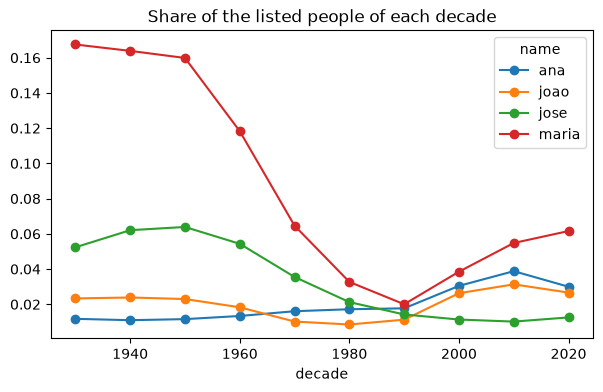

name,ana,joao,jose,maria
decade,,,,
1930,0.011751,0.023318,0.052362,0.167515
1940,0.010976,0.023861,0.062080,0.163888
1950,0.011579,0.022990,0.063906,0.159869
1960,0.013363,0.018295,0.054340,0.118272
1970,0.016071,0.010208,0.035517,0.064624
1980,0.017193,0.008530,0.021233,0.032696
1990,0.017715,0.011279,0.014230,0.020023
2000,0.030457,0.026297,0.011348,0.038521
2010,0.038807,0.031329,0.010177,0.054810


In [12]:
heads = names_decade[names_decade["name"].isin(HEADS)].copy()
heads["share"] = heads["count"] / heads["decade"].map(listed_people)
heads = heads[["decade", "name", "count", "share"]].sort_values(
    ["decade", "name"], ignore_index=True
)

heads.pivot(index="decade", columns="name", values="share").plot(
    marker="o", figsize=(7, 4), title="Share of the listed people of each decade"
)
plt.show()
display(heads.pivot(index="decade", columns="name", values="share"))

`maria` falls from 16.8% of the listed people of 1930 to 2.0% in 1990, then rises to 6.2% in 2020. `jose` peaks at 6.4% in 1950 and falls to about 1% from 2000 on, without a comparable rise. `joao` falls from 2.4% in 1940 to 0.9% in 1980 and returns to 3.1% in 2010. `ana` stays between 1.1% and 1.2% until 1950, rises to 1.8% in 1990 and 3.9% in 2010, and is at 3.0% in 2020.

Question for Jhonatan: how much of the rise of `maria`, `ana` and `joao` after 1990 comes from compound names such as Maria Eduarda, Ana Clara or João Pedro? These data cannot tell, since only the first word is counted.

## 7. Spelling

Five spelling patterns are matched with `re.search` on IBGE's form of each name (lower case, no diacritics); `any` matches a name with at least one of them.

| Pattern | Regular expression | Examples |
| --- | --- | --- |
| `kwy` | `[kwy]` | Kauã, Wesley, Yasmin |
| `th` | `th` | Thiago, Matheus, Arthur |
| `double_consonant` | `(bb\|dd\|ff\|gg\|ll\|mm\|nn\|pp\|tt\|zz)` | Allana, Emmanuel, Giovanna |
| `son_ending` | `son$` | Anderson, Emerson |
| `ton_ending` | `ton$` | Wellington, Milton |

For each decade and sex class (`all`, `f`, `m`), the share is the number of listed people whose name matches over all listed people of that decade and class:

$$s_{d,k} = \frac{\sum_{i \in k,\ i \text{ matches}} c_{d,i}}{\sum_{i \in k} c_{d,i}}.$$

In [13]:
# One flag per pattern and name, from Python's re.search on the IBGE form
pattern_flags = names_total[["name"]].copy()
for pattern, regex in SPELLING_PATTERNS.items():
    pattern_flags[pattern] = [re.search(regex, name) is not None for name in pattern_flags["name"]]
pattern_flags["any"] = pattern_flags[list(SPELLING_PATTERNS)].any(axis=1)

# One row per decade, name and pattern; the class "all" repeats every row, "f" and "m" their own
matches = decade_rows[["decade", "name", "count", "sex_class"]].merge(
    pattern_flags.melt(id_vars="name", var_name="pattern", value_name="matches"), on="name"
)
by_class = pd.concat(
    [matches.assign(sex_class="all"), matches[matches["sex_class"].isin(["f", "m"])]],
    ignore_index=True,
)
spelling = (
    by_class.assign(people=by_class["count"].where(by_class["matches"], 0))
    .groupby(["decade", "pattern", "sex_class"])
    .agg(people=("people", "sum"), names=("matches", "sum"), listed=("count", "sum"))
    .reset_index()
)
spelling["share"] = spelling["people"] / spelling["listed"]
spelling = spelling[["decade", "pattern", "sex_class", "people", "share", "names"]]

display(
    spelling[spelling["sex_class"] == "all"].pivot(
        index="decade", columns="pattern", values="share"
    )
)

pattern,any,double_consonant,kwy,son_ending,th,ton_ending
decade,,,,,,
1930,0.046046,0.004751,0.025857,0.006504,0.008458,0.002914
1940,0.036041,0.001352,0.017469,0.010977,0.003871,0.004836
1950,0.040446,0.001212,0.016502,0.015439,0.004102,0.006711
1960,0.055027,0.002165,0.019917,0.024844,0.003451,0.009480
1970,0.079302,0.006714,0.029875,0.037320,0.003314,0.011709
1980,0.121729,0.018984,0.051152,0.043037,0.013095,0.014809
1990,0.173659,0.030626,0.086955,0.043128,0.030387,0.013350
2000,0.200429,0.042625,0.122262,0.028821,0.033869,0.007774
2010,0.192198,0.051753,0.119322,0.013926,0.040479,0.003166


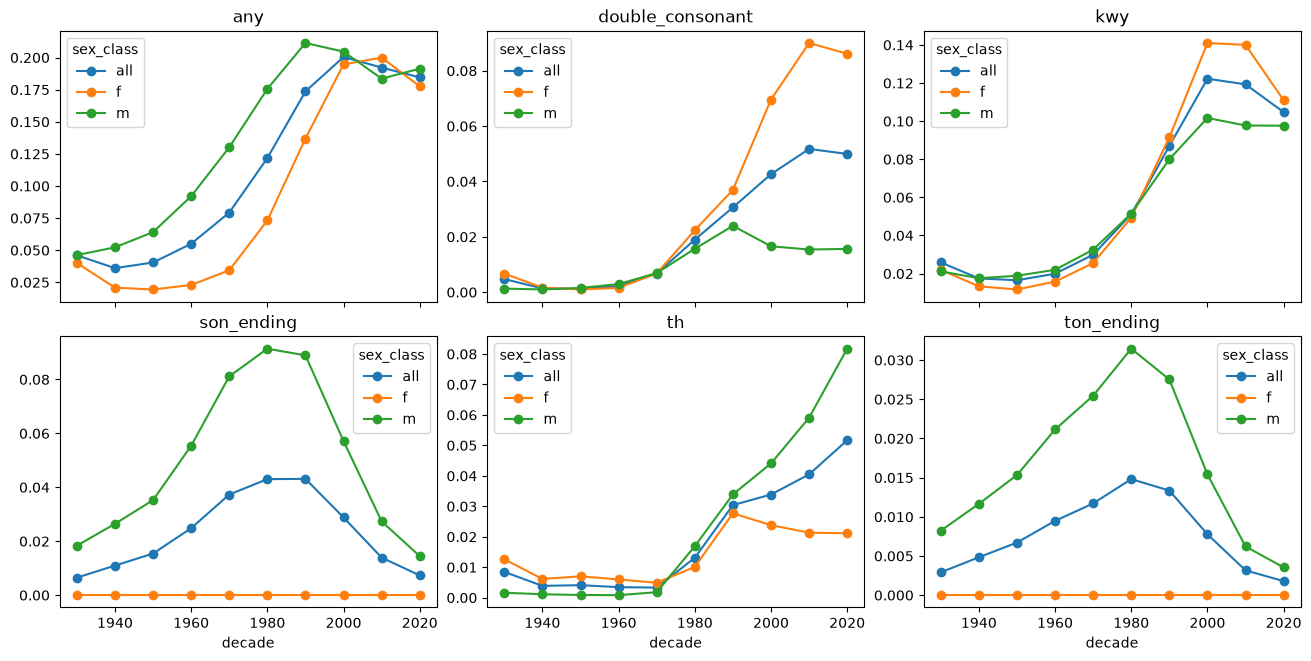

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, layout="constrained")
for ax, (pattern, rows) in zip(axes.flat, spelling.groupby("pattern"), strict=True):
    rows.pivot(index="decade", columns="sex_class", values="share").plot(
        ax=ax, marker="o", title=pattern
    )
plt.show()

The share of listed people whose name matches at least one pattern rises from 3.6% in 1940 to 20.0% in 2000 and is 19.2% in 2010 and 18.5% in 2020. `kwy` follows the same path, from 1.7% in 1940 to 12.2% in 2000. The `son` and `ton` endings rise and then fall: `son_ending` peaks at 4.3% in 1980 and 1990 and is 0.7% in 2020, and `ton_ending` peaks at 1.5% in 1980. `th` and `double_consonant` are both higher in 1930 than in the 1940s to 1960s, then rise to between 4% and 5.2% in 2010 and 2020.

By sex class, the rise is earlier among `m` names: `any` covers 13.0% of the listed people with `m` names in 1970, against 3.4% with `f` names, and the two classes are close from 2000 on (20.5% and 19.5%). `kwy` is more common among `f` names from 1990. The `son` and `ton` endings belong to `m` names: among them, `son_ending` reaches 9.1% in 1980 and `ton_ending` 3.2%, while both stay below 0.01% among `f` names. `double_consonant` reaches 9.0% of the `f` listed people in 2010, and `th` 8.2% of the `m` listed people in 2020.

In the oldest labels, `th` comes mostly from women's names (class `f`) such as `therezinha` and `thereza`; since the 1980s it comes mostly from men's names (class `m`).

Question for Jhonatan: do the `son` and `ton` endings, which rise and fall within a few decades, belong in the same story as `kwy`?

## 8. Results

The results tables, written as CSV with a header row and floats at full precision (pandas writes the shortest representation that reads back as the same number). The figures and the independent audit read them from `results/`.

In [15]:
RESULTS_DIR.mkdir(exist_ok=True)
results = {
    "diversity_by_decade.csv": diversity,
    "diversity_common_cutoff.csv": diversity_common_cutoff,
    "coverage_by_decade.csv": coverage,
    "distinctive_names.csv": distinctive,
    "heads_by_decade.csv": heads,
    "spelling_by_decade.csv": spelling,
    "sex_class_coverage.csv": sex_class_coverage,
}
for file_name, table in results.items():
    table.to_csv(RESULTS_DIR / file_name, index=False, encoding="utf-8")
    print(f"{file_name}: {len(table)} rows, columns {', '.join(table.columns)}")

diversity_by_decade.csv: 20 rows, columns decade, set, listed_people, listed_names, top1_name, top1_share, top10_share, top100_share, n50, hill_q1, hill_q2
diversity_common_cutoff.csv: 10 rows, columns decade, cutoff, names_kept, share_kept, hill_q1, hill_q2
coverage_by_decade.csv: 10 rows, columns decade, listed_people, census_people_plain, coverage_plain
distinctive_names.csv: 200 rows, columns decade, name, count, share_in_decade, share_elsewhere, log_ratio, rank
heads_by_decade.csv: 40 rows, columns decade, name, count, share
spelling_by_decade.csv: 180 rows, columns decade, pattern, sex_class, people, share, names
sex_class_coverage.csv: 30 rows, columns decade, sex_class, people, share
